# Chương 3 — Demo Hai Ứng Dụng `negFIN` (Local — Pure Julia)

Phiên bản chạy trực tiếp trên **máy local**, gọi thẳng mã nguồn `applications.jl` và `negFIN` tự viết của nhóm.

### Hướng dẫn chạy trên máy Local
1. Đảm bảo đã có sẵn dữ liệu `data/chapter3/groceries.csv` và `digits8x8.csv` trong thư mục dự án.
2. Chọn **Kernel: Julia** trong VS Code hoặc Jupyter.
3. Bấm **Run All** để chạy kiểm thử Chương 3 và cả 2 ứng dụng (*Market Basket* & *Bag of Visual Words*).

## Phần 1: Nạp Module `Applications` Từ Thư Mục Dự Án

In [1]:
using Pkg: Pkg

function find_project_root()::String
    dir = pwd()
    for _ in 1:4
        if isfile(joinpath(dir, "Project.toml")) &&
           isdir(joinpath(dir, "src", "applications"))
            return dir
        end
        parent = dirname(dir)
        parent == dir && break
        dir = parent
    end
    error("Không tìm thấy thư mục gốc chứa Project.toml")
end

const ROOT_DIR = find_project_root()
Pkg.activate(ROOT_DIR)
include(joinpath(ROOT_DIR, "src", "applications", "applications.jl"))
using .Applications: print_accuracy_table, print_top_rules_table,
    run_market_basket, run_visual_words
println("Julia version: ", VERSION)
println("Project root:  ", ROOT_DIR)

  Activating 

Julia version: 1

project at `~/Documents/Material/AI/DataMining/Frequent_Itemset_Mining`


.11.9
Project root:  /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining


## Phần 2: Chạy Kiểm Thử Tự Động Chương 3 (`tests/test_ch3_julia.jl`)

In [ ]:
cd(ROOT_DIR) do
    run(`$(Base.julia_cmd()) --project=. tests/test_ch3_julia.jl`)
end

## Phần 3: Ứng Dụng 1 — Phân Tích Giỏ Hàng (`Groceries`, `negfin_optimized`)

- Dữ liệu: 9,835 giao dịch, 169 nhóm sản phẩm (`data/chapter3/groceries.csv`).
- Ngưỡng mặc định: `minsup = 0.01`, `minconf = 0.15` (có thể đổi `:optimized` thành `:baseline` để đối chứng).
- Lưu ý: Chỉ số `Lift > 1` phản ánh **tương quan thống kê dương**, không chứng minh quan hệ nhân quả.

MARKET: 9835 transactions; 333 itemsets; 322 rules; support PASS; 0.015 sec
  [curd] => [whole milk + yogurt]: confidence=18.9%, lift=3.37. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
  [whole milk + yogurt] => [curd]: confidence=18.0%, lift=3.37. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
  [citrus fruit + other vegetables] => [root vegetables]: confidence=35.9%, lift=3.30. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
Output: /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/results/chapter3/market_basket

=== MARKET BASKET SUMMARY ===
Source: /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/data/chapter3/groceries.csv
Transactions: 9835; products: 169
Algorithm: optimized; minsup: 0.01; minconf: 0.15
Frequent itemsets: 333; association rules: 322
Mining elapsed_sec: 0.0154
Support cross-check: PASS
Top 1: [curd] => [w

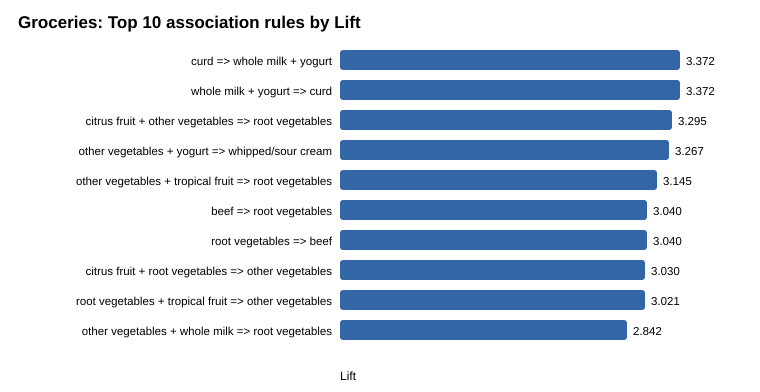

In [3]:
market_res = run_market_basket(;
    minsup=0.01,
    minconf=0.15,
    algo=:optimized,
)

market_dir = joinpath(ROOT_DIR, "results", "chapter3", "market_basket")
println("\n=== MARKET BASKET SUMMARY ===")
println(read(joinpath(market_dir, "summary.txt"), String))
println("=== TOP-10 LUẬT THEO LIFT ===")
print_top_rules_table(joinpath(market_dir, "top10_lift.csv"))
display("image/svg+xml", read(joinpath(market_dir, "top10_lift.svg"), String))

## Phần 4: Ứng Dụng 2 — Bag of Visual Words (`UCI Digits 8×8`, `negfin_optimized`)

- Trích 9 dense gradient descriptors 6 chiều/ảnh (**không phải SIFT/ORB**), học codebook K-means (`K = 16`, `seed = 42`) trên tập train, khai thác mẫu bằng `negfin_optimized` (`minsup = 0.12`).
- Đánh giá độ làm giàu đặc trưng (*Enrichment*) và độ chính xác *Nearest-Centroid* trên tập test độc lập.

VISUAL: 448 train + 152 test images; 154 itemsets, 60 patterns; support PASS
Accuracy baseline=0.7961, with patterns=0.7895
Output: /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/results/chapter3/visual_words

=== VISUAL WORDS SUMMARY ===
Dataset: UCI optical recognition digits (8x8 grayscale)
Train/test images: 448/152; seed: 42
Descriptors: 9 local gradient patches per image, 6 values per patch; NOT SIFT
K-means codebook: 16 words, trained on train images only
Algorithm: optimized; minsup: 0.12
Frequent itemsets: 154; selected patterns: 60
Mining elapsed_sec: 0.0052
Support cross-check: PASS
Nearest-centroid accuracy words only: 0.7961
Nearest-centroid accuracy + FIM patterns: 0.7895
Accuracy improvement is not guaranteed; check actual results.

=== SO SÁNH ĐỘ CHÍNH XÁC NEAREST-CENTROID ===
--------------------------------------------------------
Representation               | Features | Test Accuracy
--------------------------------------------------

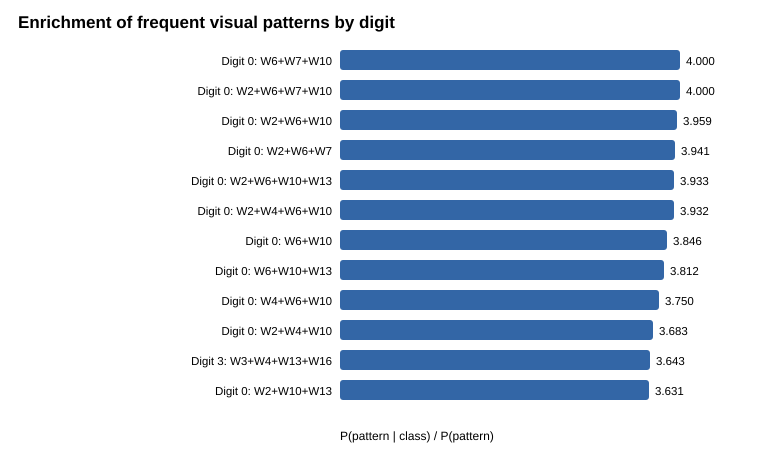

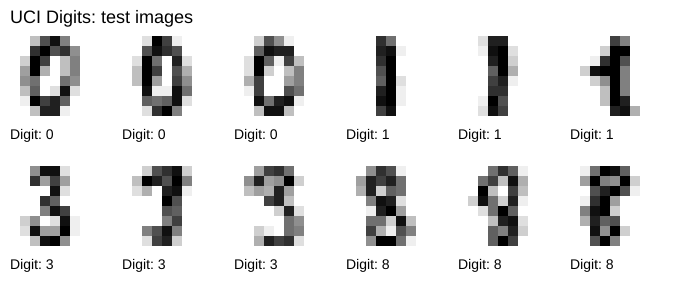

In [4]:
visual_res = run_visual_words(;
    minsup=0.12,
    words=16,
    seed=42,
    algo=:optimized,
)

visual_dir = joinpath(ROOT_DIR, "results", "chapter3", "visual_words")
println("\n=== VISUAL WORDS SUMMARY ===")
println(read(joinpath(visual_dir, "summary.txt"), String))
println("=== SO SÁNH ĐỘ CHÍNH XÁC NEAREST-CENTROID ===")
print_accuracy_table(joinpath(visual_dir, "test_accuracy_comparison.csv"))
display("image/svg+xml", read(joinpath(visual_dir, "enriched_patterns.svg"), String))
display("image/svg+xml", read(joinpath(visual_dir, "digits_samples.svg"), String))